In [1]:
import os, random, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [2]:
def show_tree(root, max_depth=3, max_items=8):
    root = Path(root)
    def _walk(p, depth):
        if depth > max_depth:
            return
        try:
            items = sorted(p.iterdir())
        except Exception:
            return
        for d in [i for i in items if i.is_dir()][:max_items]:
            n_files = sum(1 for f in d.iterdir() if f.is_file())
            print("  " * depth + f"[DIR] {d.name}  (files directly inside: {n_files})")
            _walk(d, depth + 1)
    print(root)
    _walk(root, 1)

show_tree("/kaggle/input", max_depth=4)

/kaggle/input
  [DIR] datasets  (files directly inside: 0)
    [DIR] naimulislamrayat  (files directly inside: 0)
      [DIR] mango-leaf-disease  (files directly inside: 0)
        [DIR] Mango Leaf  (files directly inside: 0)


In [3]:
DATA_DIR = "/kaggle/input/datasets/naimulislamrayat/mango-leaf-disease/Mango Leaf"
ONLY_PATH_CONTAINS = None
EXCLUDE_PATH_CONTAINS = ["augment"]

IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 25
LR = 1e-3
VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

In [4]:
records = []
for root, _, files in os.walk(DATA_DIR):
    low = root.lower()
    if ONLY_PATH_CONTAINS and ONLY_PATH_CONTAINS.lower() not in low:
        continue
    if any(k.lower() in low for k in (EXCLUDE_PATH_CONTAINS or [])):
        continue
    for f in files:
        if Path(f).suffix.lower() in VALID_EXT:
            records.append((os.path.join(root, f), os.path.basename(root)))

df = pd.DataFrame(records, columns=["path", "class_name"])
print("Total images found:", len(df))
print(df["class_name"].value_counts())
assert len(df) > 0, "No images found. Check DATA_DIR / filters."
assert df["class_name"].nunique() >= 2, "Fewer than 2 classes found. Check folders/filters."

df["parent_of_class"] = df["path"].apply(lambda p: Path(p).parent.parent.name)
print("\nImages per parent folder:")
print(df["parent_of_class"].value_counts())

class_names = sorted(df["class_name"].unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
df["label"] = df["class_name"].map(class_to_idx)
NUM_CLASSES = len(class_names)
print("\nClasses:", class_to_idx)

Total images found: 8000
class_name
Anthracnose_Au       1500
Gall Midge_AU        1500
Powdery Mildew_AU    1500
Healthy_Au           1500
Gall Midge            500
Anthracnose           500
Healthy               500
Powdery Mildew        500
Name: count, dtype: int64

Images per parent folder:
parent_of_class
Mango Leaf    8000
Name: count, dtype: int64

Classes: {'Anthracnose': 0, 'Anthracnose_Au': 1, 'Gall Midge': 2, 'Gall Midge_AU': 3, 'Healthy': 4, 'Healthy_Au': 5, 'Powdery Mildew': 6, 'Powdery Mildew_AU': 7}


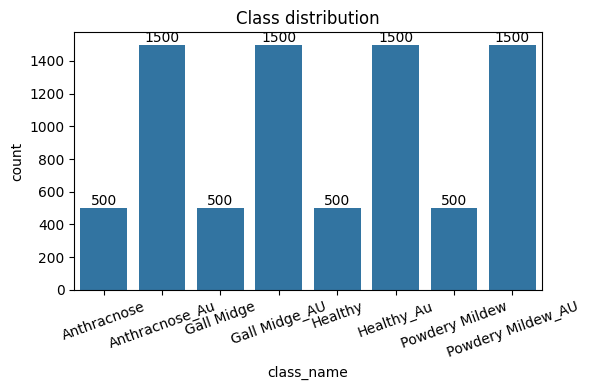

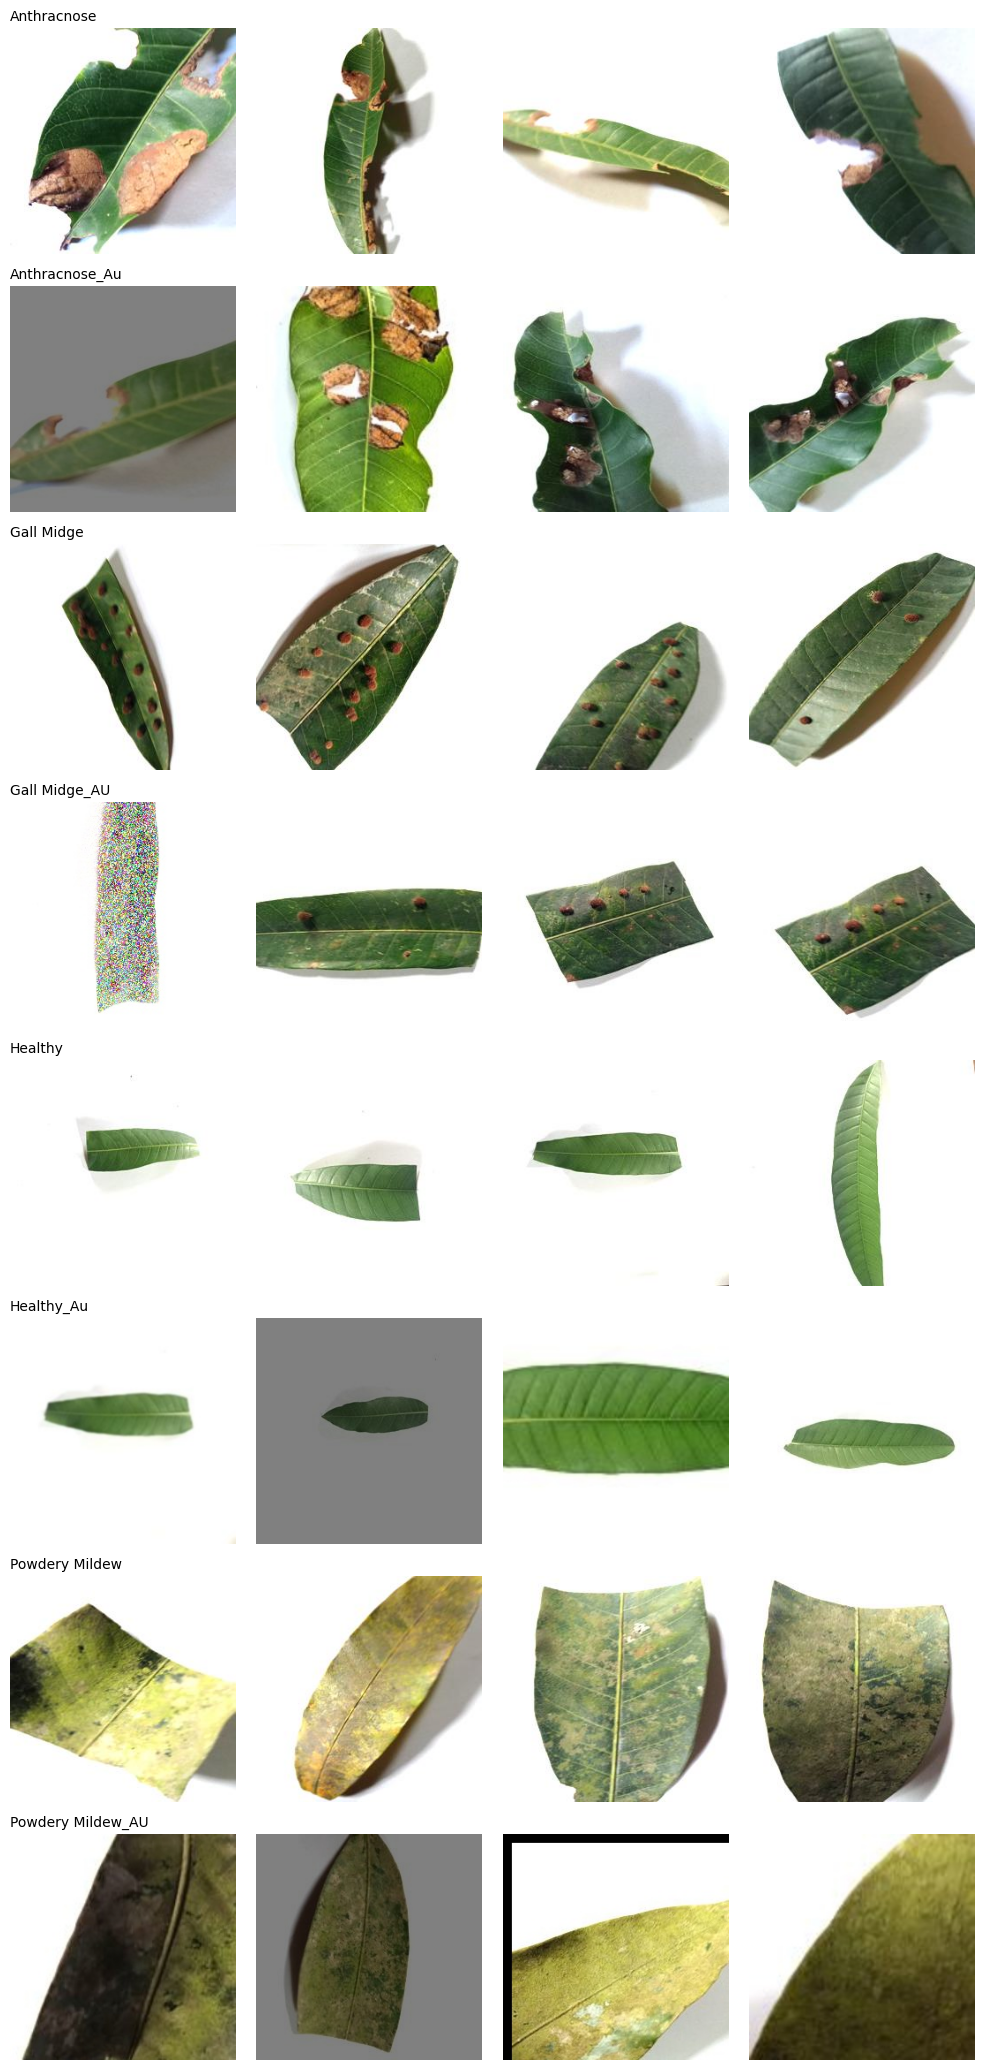

In [5]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="class_name", order=class_names)
ax.set_title("Class distribution")
plt.xticks(rotation=20)
for c in ax.containers:
    ax.bar_label(c)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(10, 2.6 * NUM_CLASSES))
axes = np.atleast_2d(axes)
for r, cname in enumerate(class_names):
    sample = df[df.class_name == cname].sample(4, random_state=SEED)
    for c, p in enumerate(sample.path):
        axes[r, c].imshow(Image.open(p).convert("RGB")); axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(cname, fontsize=10, loc="left")
plt.tight_layout(); plt.show()

In [6]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
print("Train:", len(train_df))
print("Val:", len(val_df))
print("Test:", len(test_df))

Train: 5600
Val: 1200
Test: 1200


In [7]:
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

class LeafDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths = frame["path"].tolist()
        self.labels = frame["label"].tolist()
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]

train_ds = LeafDataset(train_df, train_tf)
val_ds = LeafDataset(val_df, eval_tf)
test_ds = LeafDataset(test_df, eval_tf)

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_dl = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

img, label = train_ds[0]
print("One image tensor:", img.shape, "| label:", label)

One image tensor: torch.Size([3, 128, 128]) | label: 5


In [8]:
class MangoCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        # Convolutional blocks
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.pool = nn.MaxPool2d(2, 2)
        # Classifier: image size 128 -> 64 -> 32 -> 16 after three max-pools
        input_neurons = 64 * (IMG_SIZE // 8) * (IMG_SIZE // 8)
        self.fc1 = nn.Linear(input_neurons, 128)
        self.dropout = nn.Dropout(0.5)
        self.cls = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))   # 128 -> 64
        x = self.pool(F.relu(self.bn2(self.conv2(x))))   # 64 -> 32
        x = self.pool(F.relu(self.bn3(self.conv3(x))))   # 32 -> 16
        x = torch.flatten(x, 1)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.cls(x)

model = MangoCNN(NUM_CLASSES).to(device)
print(model)
n_params = sum(p.numel() for p in model.parameters())
print("Total parameters:", n_params)

MangoCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (cls): Linear(in_features=128, out_features=8, bias=True)
)
Total parameters: 2122120


In [9]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def run_epoch(loader, train):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for img, label in loader:
            img, label = img.to(device), label.to(device)
            if train:
                optimizer.zero_grad()
            output = model(img)
            loss = loss_fn(output, label)
            if train:
                loss.backward()   # gradient calculation
                optimizer.step()  # weight update
            total_loss += loss.item() * label.size(0)
            correct += torch.sum(torch.argmax(output, dim=1) == label).item()
            total += label.size(0)
    return total_loss / total, correct / total

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc, best_state = 0.0, None
t0 = time.time()

for ep in range(EPOCHS):
    tr_loss, tr_acc = run_epoch(train_dl, train=True)
    va_loss, va_acc = run_epoch(val_dl, train=False)
    history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss);   history["val_acc"].append(va_acc)
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    print(f"Ep {ep+1}: Train Loss {tr_loss:.4f} Acc {tr_acc:.4f} | Val Loss {va_loss:.4f} Acc {va_acc:.4f}")

train_minutes = (time.time() - t0) / 60
print(f"\nTraining time: {train_minutes:.1f} min | Best val acc: {best_val_acc:.4f}")

model.load_state_dict(best_state)   # go back to the best epoch

Ep 1: Train Loss 1.7979 Acc 0.3604 | Val Loss 1.2855 Acc 0.5475
Ep 2: Train Loss 1.4520 Acc 0.4396 | Val Loss 1.0897 Acc 0.6100
Ep 3: Train Loss 1.3601 Acc 0.4723 | Val Loss 1.3127 Acc 0.4858
Ep 4: Train Loss 1.2872 Acc 0.5011 | Val Loss 1.0708 Acc 0.5817
Ep 5: Train Loss 1.2105 Acc 0.5200 | Val Loss 0.9497 Acc 0.6375
Ep 6: Train Loss 1.1756 Acc 0.5357 | Val Loss 0.9680 Acc 0.6458
Ep 7: Train Loss 1.1323 Acc 0.5436 | Val Loss 0.8265 Acc 0.6792
Ep 8: Train Loss 1.1116 Acc 0.5823 | Val Loss 0.8184 Acc 0.7000
Ep 9: Train Loss 1.0555 Acc 0.5966 | Val Loss 0.8063 Acc 0.6867
Ep 10: Train Loss 1.0344 Acc 0.6073 | Val Loss 0.7214 Acc 0.7067
Ep 11: Train Loss 1.0378 Acc 0.6038 | Val Loss 0.8438 Acc 0.6692
Ep 12: Train Loss 0.9870 Acc 0.6164 | Val Loss 0.7836 Acc 0.6867
Ep 13: Train Loss 0.9871 Acc 0.6148 | Val Loss 0.7398 Acc 0.7133
Ep 14: Train Loss 0.9601 Acc 0.6245 | Val Loss 0.7225 Acc 0.7033
Ep 15: Train Loss 0.9816 Acc 0.6207 | Val Loss 0.6840 Acc 0.7233
Ep 16: Train Loss 0.9457 Acc 0.631

<All keys matched successfully>

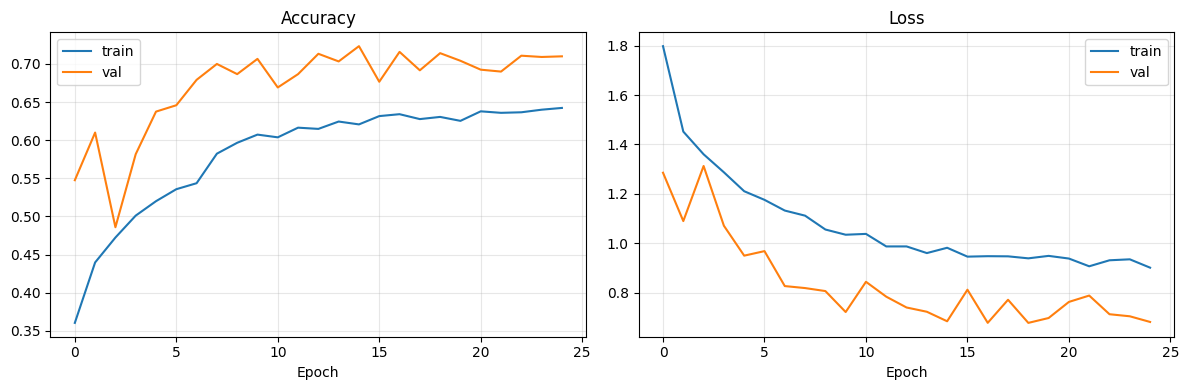

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["train_acc"], label="train"); ax[0].plot(history["val_acc"], label="val")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(history["train_loss"], label="train"); ax[1].plot(history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

Test accuracy: 0.7167

                   precision    recall  f1-score   support

      Anthracnose     0.0000    0.0000    0.0000        75
   Anthracnose_Au     0.7086    0.9511    0.8121       225
       Gall Midge     0.0000    0.0000    0.0000        75
    Gall Midge_AU     0.7163    0.9200    0.8054       225
          Healthy     0.0000    0.0000    0.0000        75
       Healthy_Au     0.7246    0.9822    0.8340       225
   Powdery Mildew     0.0000    0.0000    0.0000        75
Powdery Mildew_AU     0.7171    0.9689    0.8242       225

         accuracy                         0.7167      1200
        macro avg     0.3583    0.4778    0.4095      1200
     weighted avg     0.5375    0.7167    0.6142      1200



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


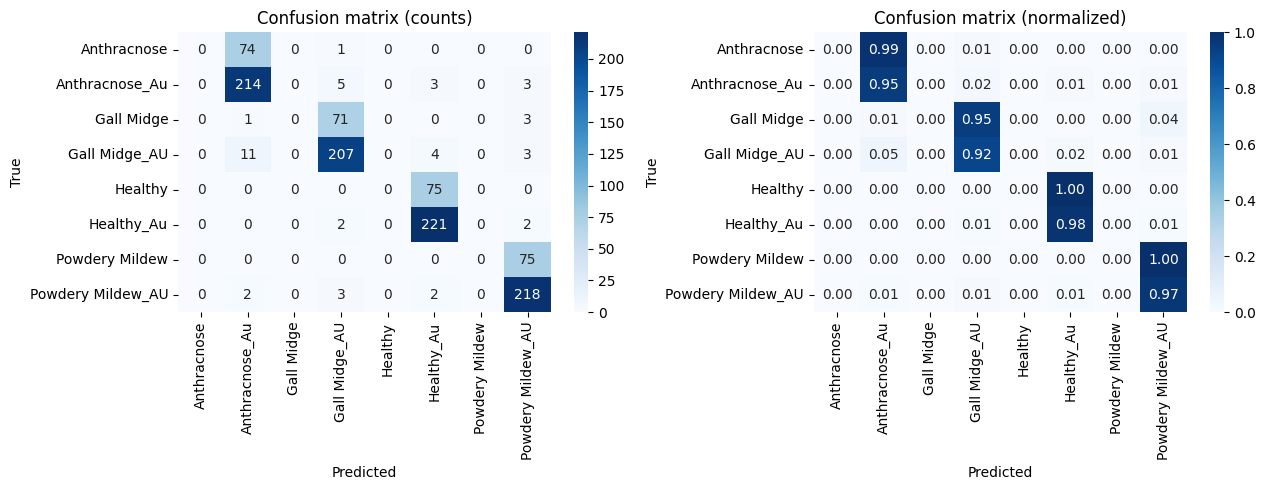

In [11]:
model.eval()
all_probs, all_true = [], []
with torch.no_grad():
    for img, label in test_dl:
        out = model(img.to(device))
        all_probs.append(F.softmax(out, dim=1).cpu())
        all_true.append(label)
probs = torch.cat(all_probs).numpy()
y_true = torch.cat(all_true).numpy()
y_pred = probs.argmax(axis=1)

test_acc = (y_pred == y_true).mean()
print(f"Test accuracy: {test_acc:.4f}\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0])
ax[0].set_title("Confusion matrix (counts)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[1])
ax[1].set_title("Confusion matrix (normalized)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("True")
plt.tight_layout(); plt.show()

In [12]:
print("Classes:", class_names)
print("Num classes:", NUM_CLASSES)
print("\nTrue label counts in test set:")
print(pd.Series([class_names[i] for i in y_true]).value_counts())
print("\nPredicted label counts:")
print(pd.Series([class_names[i] for i in y_pred]).value_counts())
print("\nLast 5 epochs of training:")
print(pd.DataFrame(history).tail(5))

Classes: ['Anthracnose', 'Anthracnose_Au', 'Gall Midge', 'Gall Midge_AU', 'Healthy', 'Healthy_Au', 'Powdery Mildew', 'Powdery Mildew_AU']
Num classes: 8

True label counts in test set:
Healthy_Au           225
Powdery Mildew_AU    225
Gall Midge_AU        225
Anthracnose_Au       225
Powdery Mildew        75
Gall Midge            75
Anthracnose           75
Healthy               75
Name: count, dtype: int64

Predicted label counts:
Healthy_Au           305
Powdery Mildew_AU    304
Anthracnose_Au       302
Gall Midge_AU        289
Name: count, dtype: int64

Last 5 epochs of training:
    train_loss  train_acc  val_loss   val_acc
20    0.937953   0.637857  0.762398  0.692500
21    0.906601   0.635893  0.788038  0.690000
22    0.930935   0.636607  0.712501  0.710833
23    0.934827   0.640000  0.704189  0.709167
24    0.901025   0.642321  0.681224  0.710000


Misclassified: 340 of 1200


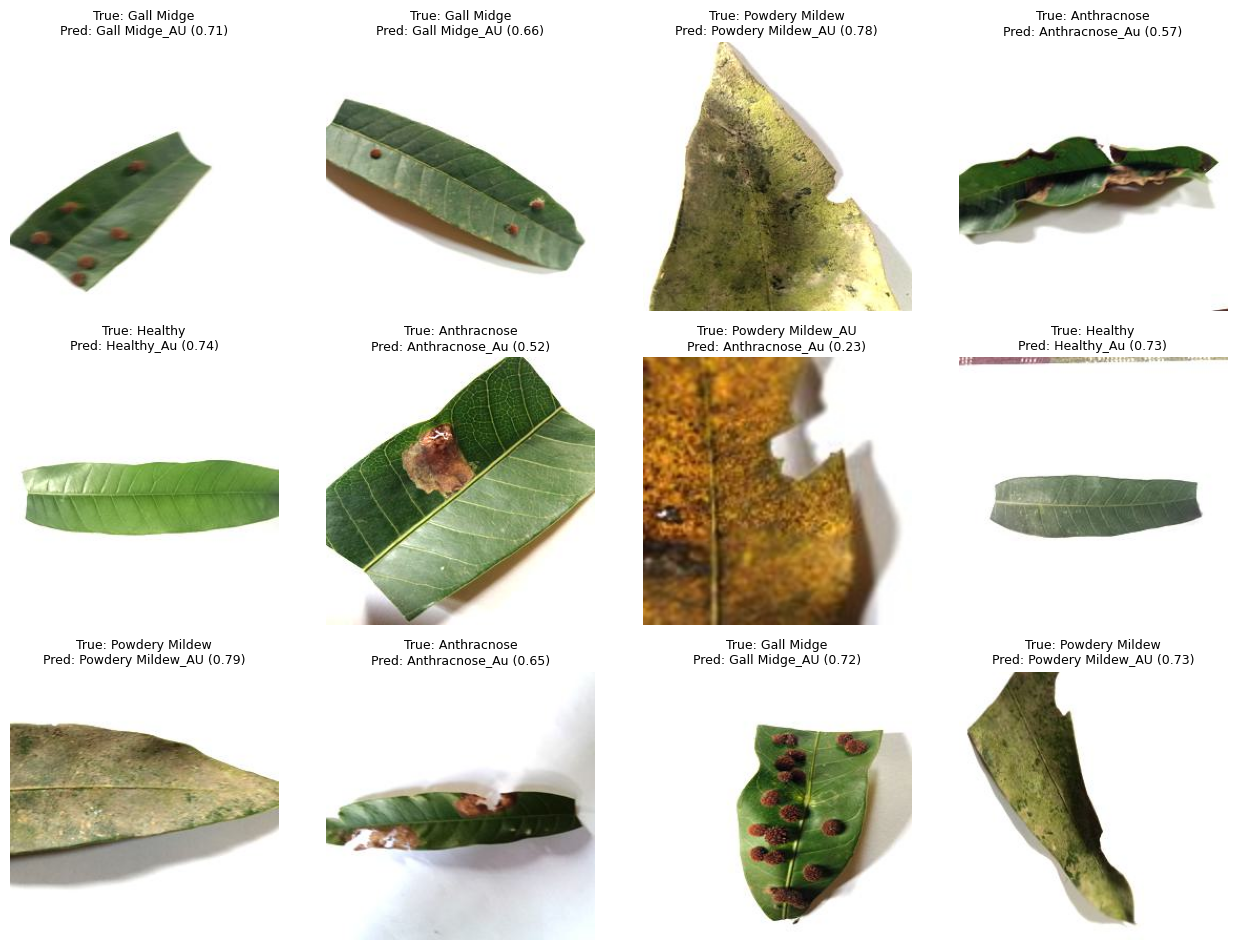

In [13]:
wrong = np.where(y_pred != y_true)[0]
print(f"Misclassified: {len(wrong)} of {len(y_true)}")
show = wrong[:12]
if len(show) > 0:
    cols = 4
    rows = int(np.ceil(len(show) / cols))
    plt.figure(figsize=(3.2 * cols, 3.2 * rows))
    for k, i in enumerate(show):
        plt.subplot(rows, cols, k + 1)
        plt.imshow(Image.open(test_df.iloc[i]["path"]).convert("RGB")); plt.axis("off")
        plt.title(f"True: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]} ({probs[i, y_pred[i]]:.2f})", fontsize=9)
    plt.tight_layout(); plt.show()

Early feature maps: torch.Size([16, 128, 128])
Last feature maps: torch.Size([64, 32, 32])


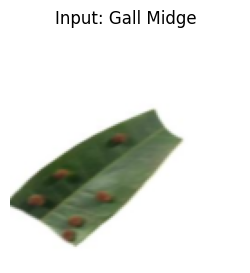

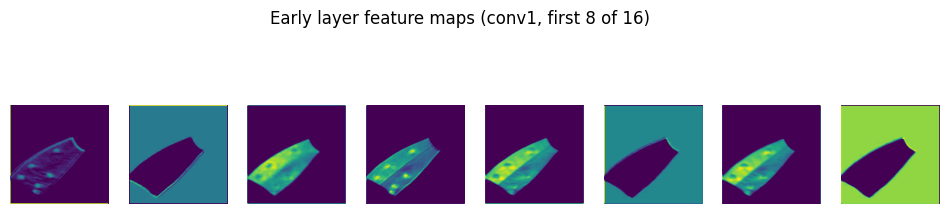

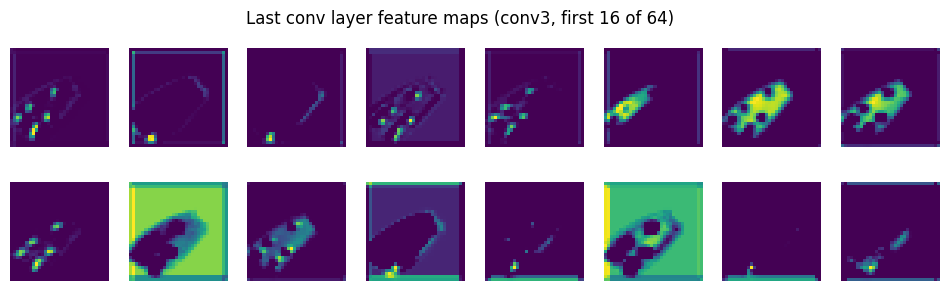

In [14]:
img, label = test_ds[0]
x = img.unsqueeze(0).to(device)
model.eval()
with torch.no_grad():
    x1 = F.relu(model.bn1(model.conv1(x)))
    early = x1.cpu()[0]                      # early layer features: 16 x 128 x 128
    x2 = F.relu(model.bn2(model.conv2(model.pool(x1))))
    x3 = F.relu(model.bn3(model.conv3(model.pool(x2))))
    last = x3.cpu()[0]                       # last conv layer features: 64 x 32 x 32

print("Early feature maps:", early.shape)
print("Last feature maps:", last.shape)

plt.figure(figsize=(3, 3))
plt.imshow(img.permute(1, 2, 0)); plt.axis("off")
plt.title(f"Input: {class_names[label]}")
plt.show()

plt.figure(figsize=(12, 3))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(early[i], cmap='viridis'); plt.axis('off')
plt.suptitle("Early layer feature maps (conv1, first 8 of 16)")
plt.show()

plt.figure(figsize=(12, 3.2))
for i in range(16):
    plt.subplot(2, 8, i + 1)
    plt.imshow(last[i], cmap='viridis'); plt.axis('off')
plt.suptitle("Last conv layer feature maps (conv3, first 16 of 64)")
plt.show()

In [15]:
report = classification_report(y_true, y_pred, target_names=class_names,
                               output_dict=True, zero_division=0)
summary = {
    "images_used": int(len(df)),
    "num_classes": int(NUM_CLASSES),
    "train/val/test": f"{len(train_df)}/{len(val_df)}/{len(test_df)}",
    "image_size": f"{IMG_SIZE}x{IMG_SIZE}",
    "total_parameters": int(n_params),
    "epochs": EPOCHS,
    "training_minutes": round(train_minutes, 1),
    "best_val_accuracy": round(float(best_val_acc), 4),
    "test_accuracy": round(float(test_acc), 4),
    "test_macro_f1": round(float(report["macro avg"]["f1-score"]), 4),
}
print(json.dumps(summary, indent=2))

torch.save(model.state_dict(), "mango_cnn.pth")
pd.DataFrame(history).to_csv("training_history.csv", index=False)
pd.DataFrame(report).T.to_csv("classification_report.csv")
with open("summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print("\nSaved: mango_cnn.pth, training_history.csv, classification_report.csv, summary.json")

{
  "images_used": 8000,
  "num_classes": 8,
  "train/val/test": "5600/1200/1200",
  "image_size": "128x128",
  "total_parameters": 2122120,
  "epochs": 25,
  "training_minutes": 8.2,
  "best_val_accuracy": 0.7233,
  "test_accuracy": 0.7167,
  "test_macro_f1": 0.4095
}

Saved: mango_cnn.pth, training_history.csv, classification_report.csv, summary.json
